In [1]:

import pandas as pd
import numpy as np

url = 'https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv'
df = pd.read_csv(url)
print(df.head())
print(df.dtypes)

df['posted_at'] = pd.to_datetime(df['posted_at'], errors='coerce')

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

/tmp/ipykernel_905/3697084928.py:9: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(df['posted_at'], errors='coerce')


In [4]:
# data cleaning

print(df.isnull().sum())


df['likes'].fillna(df['likes'].median(), inplace=True)
df['comments'].fillna(0, inplace=True)
df.dropna(subset=['posted_at'], inplace=True)


df.drop_duplicates(inplace=True)

df['gender'] = df['gender'].str.lower().replace({'m':'male','f':'female'})

df['likes'] = df['likes'].clip(lower=0)
df['comments'] = df['comments'].clip(lower=0)
df['shares'] = df['shares'].clip(lower=0)


df['hashtag_count'] = df['hashtags'].apply(lambda x: len(str(x).split('#'))-1)

df['sentiment'] = df['sentiment'].str.lower().replace({'pos':'positive','neg':'negative','neu':'neutral'})

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes                 0
comments              0
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
hashtag_count         0
dtype: int64


/tmp/ipykernel_905/2335508631.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['likes'].fillna(df['likes'].median(), inplace=True)
/tmp/ipykernel_905/2335508631.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', 

In [8]:
#Data Exploration
print(df.shape)
print(df.info())
print(df.describe())

print(df['post_type'].value_counts())
print(df['country'].nunique())

corr = df.corr(numeric_only=True)
print(corr)

print(df.groupby('post_type')['likes'].mean())
print(df.groupby('country')['impression_count'].mean())


(5000, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            4850 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            4850 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified  

In [9]:
# Data Wrangling

# Create engagement score
df['engagement_score'] = df['likes'] + df['comments'] + df['shares']

# Log transform (optional)
df['log_likes'] = np.log1p(df['likes'])

# Groupby summaries
eng_summary = df.groupby(['post_type','country','sentiment'])['engagement_score'].mean().reset_index()
print(eng_summary.head())


  post_type    country sentiment  engagement_score
0     image  Australia  negative      10082.763158
1     image  Australia   neutral      12781.012195
2     image  Australia  positive      12756.974138
3     image     Brazil  negative      10218.800000
4     image     Brazil   neutral      11158.844444


In [12]:
#Statistical Analysis

metrics = ['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']

for col in metrics:
    print(f"--- {col} ---")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Std Dev:", df[col].std())
    print("Variance:", df[col].var())
    print("Percentiles:", df[col].quantile([0.25,0.5,0.75]).to_dict())


--- likes ---
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Std Dev: 5702.293017183876
Variance: 32516145.653823998
Percentiles: {0.25: 5235.0, 0.5: 10105.5, 0.75: 14959.0}
--- comments ---
Mean: 1457.1298
Median: 1454.5
Mode: 0.0
Std Dev: 893.9176010614476
Variance: 799088.6774874534
Percentiles: {0.25: 675.0, 0.5: 1454.5, 0.75: 2235.25}
--- shares ---
Mean: 1002.6294845360825
Median: 1012.0
Mode: 138.0
Std Dev: 579.6151583034584
Variance: 335953.7317351432
Percentiles: {0.25: 498.0, 0.5: 1012.0, 0.75: 1501.0}
--- watch_time_sec ---
Mean: 4014.5032
Median: 4034.5
Mode: 916
Std Dev: 2308.096459042085
Variance: 5327309.26424261
Percentiles: {0.25: 2017.75, 0.5: 4034.5, 0.75: 6020.25}
--- engagement_rate ---
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909
Std Dev: 5.318029222661535
Variance: 28.281434813082043
Percentiles: {0.25: 0.14578108750000002, 0.5: 0.2538959065, 0.75: 0.504793702}
--- follower_count ---
Mean: 393698.2248
Median: 388982.0
Mode: 497502
Std Dev: 2309

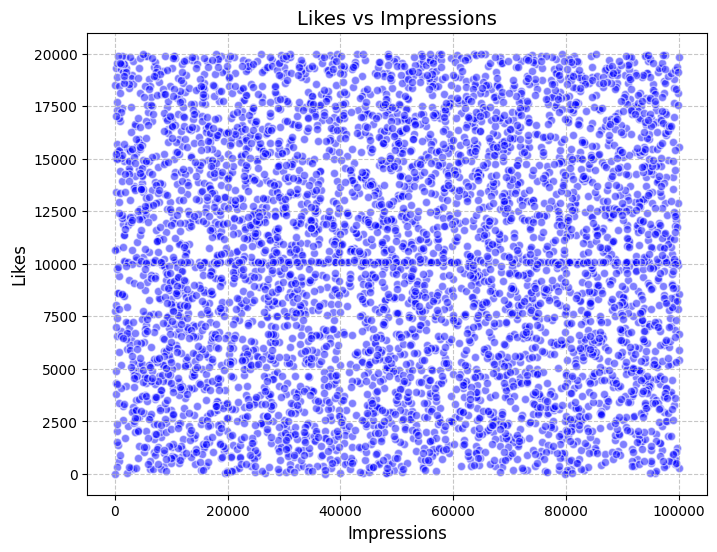

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(8,6))

# Scatter plot with transparency and white edge for clarity
plt.scatter(df['impression_count'], df['likes'],
            alpha=0.5, c='blue', edgecolors='w')

# Labels and title
plt.xlabel("Impressions", fontsize=12)
plt.ylabel("Likes", fontsize=12)
plt.title("Likes vs Impressions", fontsize=14)

# Add grid for readability
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()


<Axes: title={'center': 'Daily Engagement Trend'}, xlabel='posted_at'>

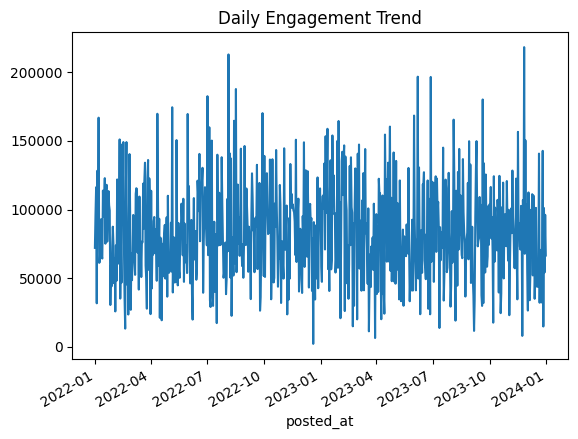

In [19]:
# Line: daily engagement trend
daily_eng = df.groupby('posted_at')['engagement_score'].sum()
daily_eng.plot(kind='line', title="Daily Engagement Trend")

<Axes: title={'center': 'Posts by Category'}, xlabel='post_type'>

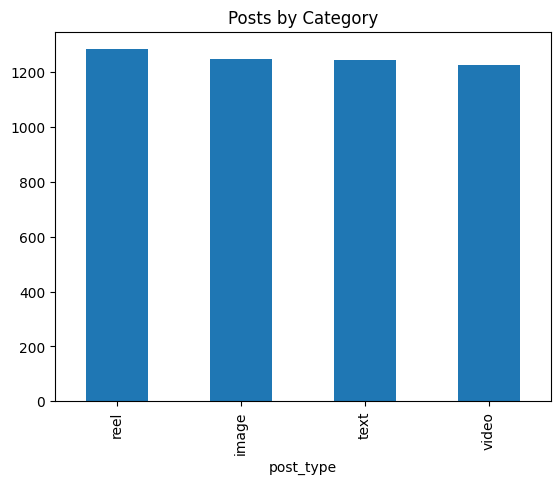

In [20]:
# Bar: posts by category
df['post_type'].value_counts().plot(kind='bar', title="Posts by Category")

<Axes: ylabel='count'>

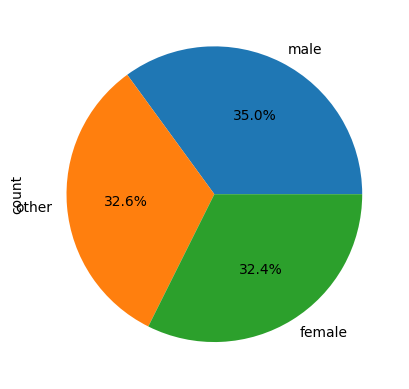

In [21]:
# Pie: gender distribution
df['gender'].value_counts().plot(kind='pie', autopct='%1.1f%%')

<Axes: title={'center': 'Age Distribution'}, ylabel='Frequency'>

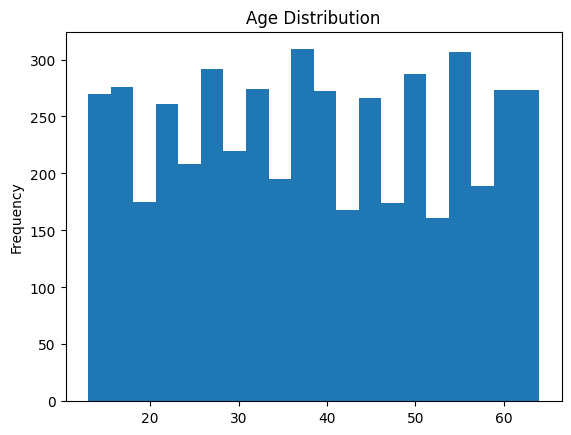

In [22]:
# Histogram: age
df['age'].plot(kind='hist', bins=20, title="Age Distribution")

<Axes: xlabel='engagement_rate'>

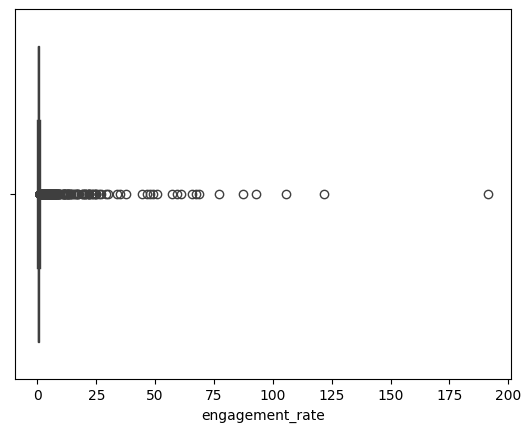

In [23]:
# Box: engagement rate
sns.boxplot(x=df['engagement_rate'])

<Axes: xlabel='post_type', ylabel='count'>

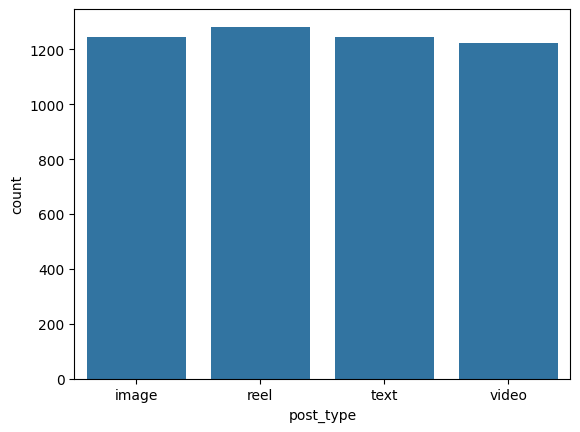

In [24]:
# Seaborn count plot: post type
sns.countplot(x='post_type', data=df)

<Axes: >

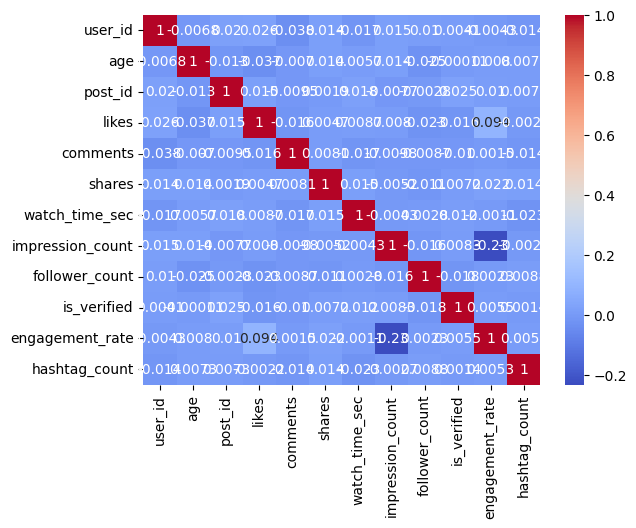

In [25]:
# Heatmap: correlation matrix
sns.heatmap(corr, annot=True, cmap="coolwarm")

In [26]:
# Plotly interactive line chart
fig = px.line(daily_eng, x=daily_eng.index, y=daily_eng.values, title="Interactive Daily Engagement")
fig.show()